#### 加载常用数据包，定义全局变量范围

In [1]:
from pathlib import Path  # 导入路径处理工具
import random  # 导入 Python 内置随机数模块
import matplotlib.pyplot as plt  # 导入绘图库 matplotlib
import numpy as np  # 导入数值计算库 numpy
import pandas as pd  # 导入数据分析库 pandas
import scipy.io as sio
from IPython.display import display  # 导入 Notebook 中展示对象的 display 函数
from sklearn.model_selection import train_test_split  # 导入 sklearn 的数据集划分函数

RANDOM_SEED = 42  # 统一设置全局随机数种子
random.seed(RANDOM_SEED)  # 固定 Python 内置随机数种子
np.random.seed(RANDOM_SEED)  # 固定 numpy 随机数种子
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans'] # 设置中文字体以避免乱码
plt.rcParams['axes.unicode_minus'] = False  # 解决图表中负号显示为方块的问题

#### 利用scipy包读取.mat文件数据，其中较多使用相对路径，例如
#### 相对路径可写为： r"B007_0.mat"
#### 绝对路径可写为： /Users/leonshang/Desktop/cwru/B007_0.mat
#### 使用相对路径更多一些，当移动项目文件夹位置时，里面的文件路径不会受到影响


In [2]:
sample_mat = sio.loadmat(r"B007_0.mat") #定义了一个sample_mat用于存储一个mat文件中的数据
print(sample_mat.keys()) #打印出列表中所有的字段
print(sample_mat['X118_DE_time'].shape,sample_mat['X118_DE_time']) #查看数据的行数，类型
print(sample_mat['X118_FE_time'].shape)
print(sample_mat['X118_BA_time'].shape)
print(sample_mat['X118RPM'].shape,sample_mat['X118RPM'])

sample_mat = sio.loadmat(r"B007_1.mat")
print(sample_mat.keys())
print(sample_mat['X119_DE_time'].shape)
print(sample_mat['X119_FE_time'].shape)
print(sample_mat['X119_BA_time'].shape)
print(sample_mat['X119RPM'].shape,sample_mat['X119RPM'])

dict_keys(['__header__', '__version__', '__globals__', 'X118_DE_time', 'X118_FE_time', 'X118_BA_time', 'X118RPM'])
(122571, 1) [[-0.0027614 ]
 [-0.09632403]
 [ 0.11370459]
 ...
 [-0.07829373]
 [-0.14911545]
 [ 0.02111657]]
(122571, 1)
(122571, 1)
(1, 1) [[1796]]
dict_keys(['__header__', '__version__', '__globals__', 'X119_DE_time', 'X119_FE_time', 'X119_BA_time', 'X119RPM'])
(121410, 1)
(121410, 1)
(121410, 1)
(1, 1) [[1772]]


#### 定义保存路径，创建文件夹，对于正常数据和外圈异常数据分别进行保存

In [3]:
TRAIN_CONDITION = '0HP'  # 设置训练集和验证集对应的工况
TEST_CONDITION = '1HP'  # 设置测试集对应的工况
WINDOW_SIZE = 1024  # 设置滑动窗口的长度
STEP_SIZE = 512  # 设置滑动窗口的步长

DATA_DIR = Path('/Users/leonshang/Desktop/cwru')  # 设置原始 CWRU 数据所在目录
SAVE_PATH = Path('processed') / f'cwru_{TRAIN_CONDITION.lower()}_trainval_{TEST_CONDITION.lower()}_test_w{WINDOW_SIZE}_s{STEP_SIZE}.npz'  # 设置处理后 npz 文件的保存路径
SAVE_PATH.parent.mkdir(exist_ok=True)  # 如果保存目录不存在则自动创建

LABEL_MAPPINGS = {  # 定义不同工况下文件名到类别编号的映射字典
    '0HP': {  # 定义 0HP 工况下的标签映射
        'Normal_0.mat': 0, 'B007_0.mat': 1, 'B014_0.mat': 1, 'B021_0.mat': 1,  # 映射正常与滚动体故障文件
        'IR007_0.mat': 2, 'IR014_0.mat': 2, 'IR021_0.mat': 2,  # 映射内圈故障文件
        'OR0076_0.mat': 3, 'OR0146_0.mat': 3, 'OR0216_0.mat': 3  # 映射外圈故障文件
    },  # 结束 0HP 工况映射
    '1HP': {  # 定义 1HP 工况下的标签映射
        'Normal_1.mat': 0, 'B007_1.mat': 1, 'B014_1.mat': 1, 'B021_1.mat': 1,  # 映射正常与滚动体故障文件
        'IR007_1.mat': 2, 'IR014_1.mat': 2, 'IR021_1.mat': 2,  # 映射内圈故障文件
        'OR0076_1.mat': 3, 'OR0146_1.mat': 3, 'OR0216_1.mat': 3  # 映射外圈故障文件
    },  # 结束 1HP 工况映射
    '2HP': {  # 定义 2HP 工况下的标签映射
        'Normal_2.mat': 0, 'B007_2.mat': 1, 'B014_2.mat': 1, 'B021_2.mat': 1,  # 映射正常与滚动体故障文件
        'IR007_2.mat': 2, 'IR014_2.mat': 2, 'IR021_2.mat': 2,  # 映射内圈故障文件
        'OR0076_2.mat': 3, 'OR0146_2.mat': 3, 'OR0216_2.mat': 3  # 映射外圈故障文件
    },  # 结束 2HP 工况映射
    '3HP': {  # 定义 3HP 工况下的标签映射
        'Normal_3.mat': 0, 'B007_3.mat': 1, 'B014_3.mat': 1, 'B021_3.mat': 1,  # 映射正常与滚动体故障文件
        'IR007_3.mat': 2, 'IR014_3.mat': 2, 'IR021_3.mat': 2,  # 映射内圈故障文件
        'OR0076_3.mat': 3, 'OR0146_3.mat': 3, 'OR0216_3.mat': 3  # 映射外圈故障文件
    }  # 结束 3HP 工况映射
}  # 结束全部标签映射定义

LABEL_NAMES = ['正常', '滚动体故障', '内圈故障', '外圈故障']  # 定义类别编号对应的中文名称
TRAIN_MAPPING = LABEL_MAPPINGS[TRAIN_CONDITION]  # 取出训练工况对应的文件映射关系
TEST_MAPPING = LABEL_MAPPINGS[TEST_CONDITION]  # 取出测试工况对应的文件映射关系

print('训练/验证工况:', TRAIN_CONDITION)  # 打印训练与验证所使用的工况
print('测试工况:', TEST_CONDITION)  # 打印测试所使用的工况
print('保存路径:', SAVE_PATH)  # 打印处理结果的保存路径

训练/验证工况: 0HP
测试工况: 1HP
保存路径: processed/cwru_0hp_trainval_1hp_test_w1024_s512.npz


#### 滑动窗口进行读取与滑动窗口切片的处理

In [4]:
# 读取 0HP 数据并做滑动窗口切片
train_all_x = []  # 创建列表用于保存所有训练工况样本切片
train_all_y = []  # 创建列表用于保存所有训练工况标签
train_summary_rows = []  # 创建列表用于保存训练工况统计信息

for file_name, label in TRAIN_MAPPING.items():  # 遍历训练工况下的每个文件及其类别标签
    mat_data = sio.loadmat(DATA_DIR / file_name)  # 读取当前 mat 文件内容

    signal_key = None  # 初始化振动信号对应的键名
    for key in mat_data.keys():  # 遍历当前 mat 文件中的所有键名
        if key.endswith('_DE_time'):  # 找到驱动端振动信号对应的键名
            signal_key = key
            break  # 找到目标键名后立即结束循环

    signal = mat_data[signal_key].squeeze().astype(np.float32)  # 读取振动信号并转换为一维 float32 数组

    #滑动窗口的划分,确定起始位置，长度
    start_list = np.arange(0, len(signal) - WINDOW_SIZE + 1, STEP_SIZE)  # 生成所有滑动窗口的起始位置
    windows = np.array([signal[start:start + WINDOW_SIZE] for start in start_list], dtype=np.float32)  # 按窗口长度切分信号并堆叠为二维数组
    labels = np.full(len(windows), label, dtype=np.int64)  # 为当前文件生成与切片数量一致的标签数组

    train_all_x.append(windows)  # 将当前文件的全部切片加入训练样本列表
    train_all_y.append(labels)  # 将当前文件的全部标签加入训练标签列表


X_train_all = np.concatenate(train_all_x, axis=0)  # 将所有训练工况切片按行拼接为总样本数组
y_train_all = np.concatenate(train_all_y, axis=0)  # 将所有训练工况标签拼接为总标签数组

print('0HP 总样本数:', len(X_train_all))  # 窗口切片总数
print('单个样本长度:', X_train_all.shape[1])  # 每个窗口长度

0HP 总样本数: 2605
单个样本长度: 1024


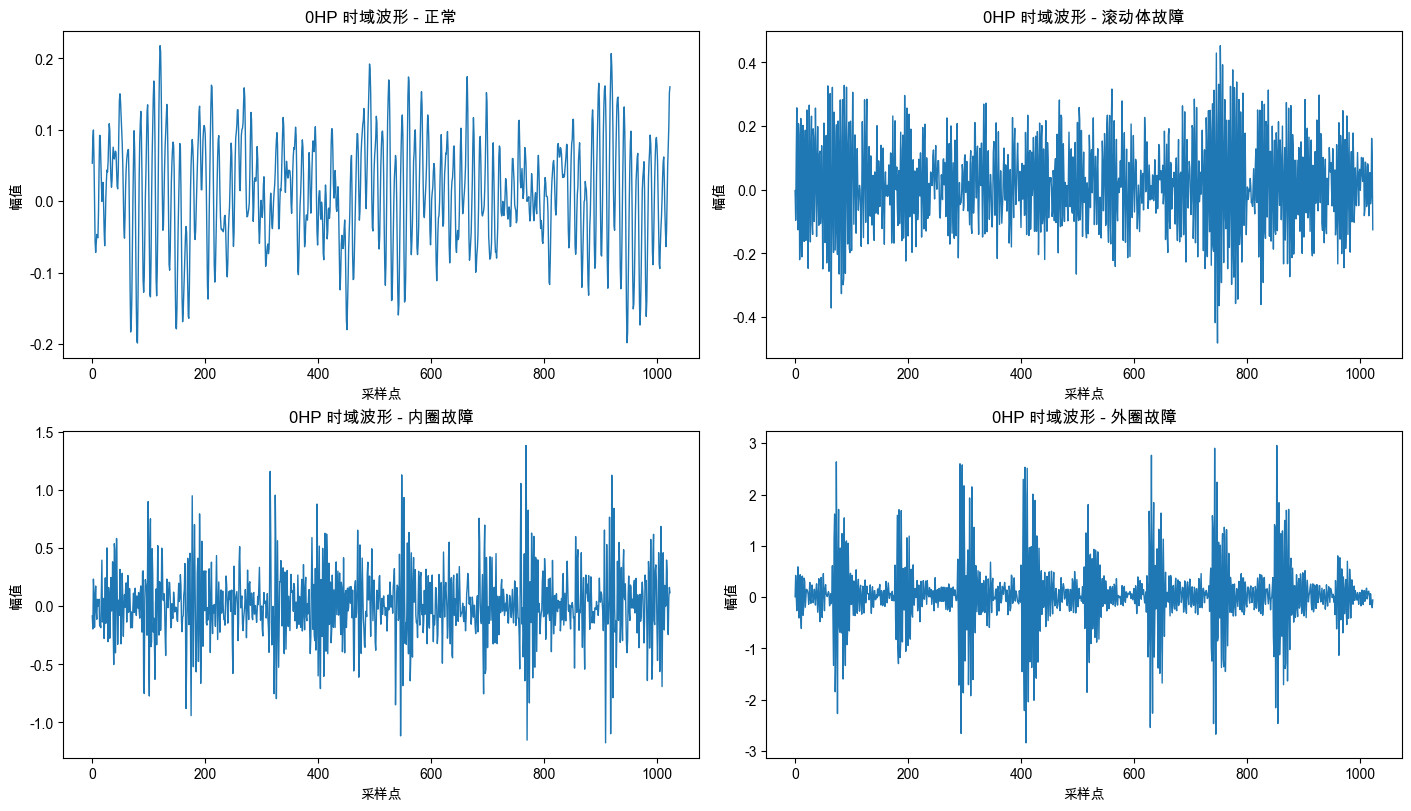

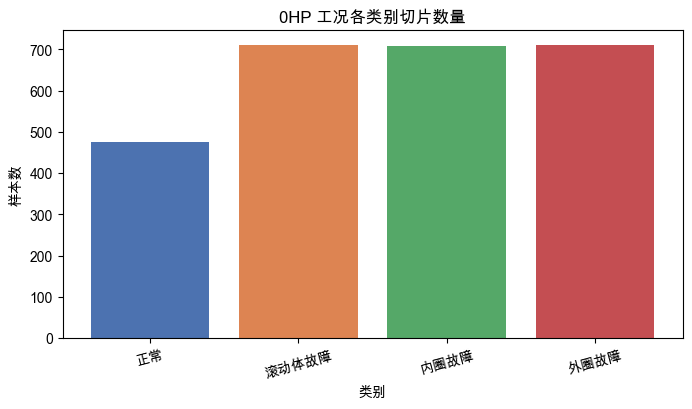

In [5]:
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)  # 创建 2 行 2 列子图用于展示四个类别的时域波形
for ax, label in zip(axes.flat, range(len(LABEL_NAMES))):  # 遍历每个子图对象和每个类别编号
    idx = np.where(y_train_all == label)[0][0]  # 找到当前类别在总样本中的第一个样本索引
    ax.plot(X_train_all[idx], linewidth=1)  # 绘制当前类别的一个示例时域波形
    ax.set_title(f'0HP 时域波形 - {LABEL_NAMES[label]}')  # 设置当前子图标题
    ax.set_xlabel('采样点')  # 设置横坐标标签为采样点
    ax.set_ylabel('幅值')  # 设置纵坐标标签为幅值
plt.show()  # 显示时域波形图

count_series_train = pd.Series(y_train_all).map(lambda i: LABEL_NAMES[i]).value_counts().reindex(LABEL_NAMES)  # 统计训练工况下各类别切片数量并按类别名称顺序重排
plt.figure(figsize=(8, 4))  # 创建类别样本数柱状图画布
plt.bar(count_series_train.index, count_series_train.values, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])  # 绘制训练工况各类别样本数柱状图
plt.title('0HP 工况各类别切片数量')  # 设置柱状图标题
plt.xlabel('类别')  # 设置横坐标标签为类别
plt.ylabel('样本数')  # 设置纵坐标标签为样本数
plt.xticks(rotation=15)  # 将横坐标文字旋转 15 度以防重叠
plt.show()  # 显示类别样本数柱状图

#### 按照0hp的数据区分训练集和验证机的划分，按照训练集0.8,测试机0.2的比例进行

In [6]:
# 按类别划分 0HP 的训练集和验证集
X_train, X_val, y_train, y_val = train_test_split(  # 使用 sklearn 按类别分层划分训练集和验证集
    X_train_all,  # 传入全部训练工况样本
    y_train_all,  # 传入全部训练工况标签
    train_size=0.8,  # 指定训练集所占比例
    test_size=0.2,  # 指定验证集所占比例
    random_state=RANDOM_SEED,  # 指定随机种子以保证划分结果可复现
    stratify=y_train_all  # 按标签分层抽样以保持类别分布一致
)  # 完成训练集和验证集划分


print(X_train.shape,y_train.shape)  # 打印训练集样本数组形状
print(X_val.shape,y_val.shape)  # 打印验证集样本数组形状


(2084, 1024) (2084,)
(521, 1024) (521,)


#### 对1hp进行类似数据处理，可视化处理以及测试集和训练集的划分

X_test: (3074, 1024)
y_test: (3074,)


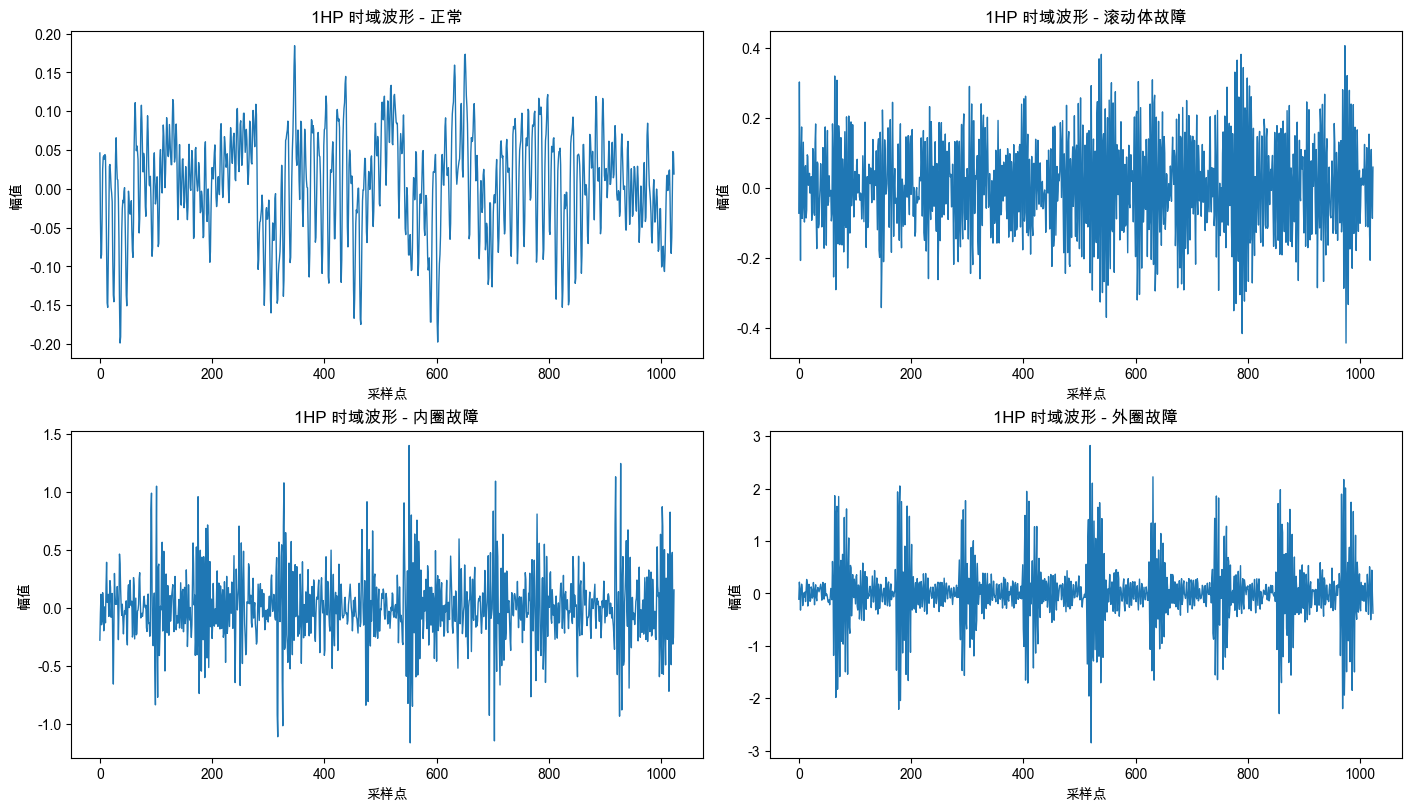

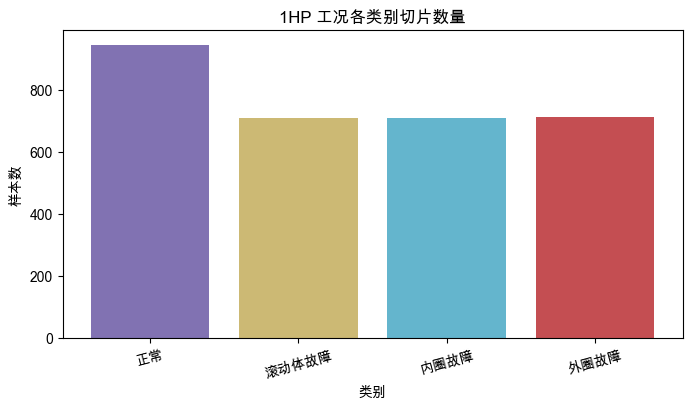

In [7]:
# 读取 1HP 数据并作为测试集
test_all_x = []  # 创建列表用于保存所有测试工况样本切片
test_all_y = []  # 创建列表用于保存所有测试工况标签
test_summary_rows = []  # 创建列表用于保存测试工况统计信息

for file_name, label in TEST_MAPPING.items():  # 遍历测试工况下的每个文件及其类别标签
    mat_data = sio.loadmat(DATA_DIR / file_name)  # 读取当前测试 mat 文件内容

    signal_key = None  # 初始化测试信号对应的键名
    for key in mat_data.keys():  # 遍历当前测试 mat 文件中的所有键名
        if key.endswith('_DE_time'):  # 找到驱动端振动信号对应的键名
            signal_key = key  # 保存测试信号键名
            break  # 找到目标键名后立即结束循环

    signal = mat_data[signal_key].squeeze().astype(np.float32)  # 读取测试振动信号并转换为一维 float32 数组
    start_list = np.arange(0, len(signal) - WINDOW_SIZE + 1, STEP_SIZE)  # 生成测试信号的所有滑动窗口起始位置
    windows = np.array([signal[start:start + WINDOW_SIZE] for start in start_list], dtype=np.float32)  # 按窗口长度切分测试信号并堆叠为二维数组
    labels = np.full(len(windows), label, dtype=np.int64)  # 为当前测试文件生成与切片数量一致的标签数组

    test_all_x.append(windows)  # 将当前测试文件的全部切片加入测试样本列表
    test_all_y.append(labels)  # 将当前测试文件的全部标签加入测试标签列表



X_test = np.concatenate(test_all_x, axis=0)  # 将所有测试工况切片按行拼接为测试样本数组
y_test = np.concatenate(test_all_y, axis=0)  # 将所有测试工况标签拼接为测试标签数组

print('X_test:', X_test.shape)  # 打印测试集样本数组形状
print('y_test:', y_test.shape)  # 打印测试集标签数组形状


# 可视化
# 1HP 时域可视化
fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)  # 创建 2 行 2 列子图用于展示四个测试类别的时域波形
for ax, label in zip(axes.flat, range(len(LABEL_NAMES))):  # 遍历每个子图对象和每个测试类别编号
    idx = np.where(y_test == label)[0][0]  # 找到当前测试类别在测试样本中的第一个样本索引
    ax.plot(X_test[idx], linewidth=1)  # 绘制当前测试类别的一个示例时域波形
    ax.set_title(f'1HP 时域波形 - {LABEL_NAMES[label]}')  # 设置当前测试子图标题
    ax.set_xlabel('采样点')  # 设置横坐标标签为采样点
    ax.set_ylabel('幅值')  # 设置纵坐标标签为幅值
plt.show()  # 显示测试时域波形图

count_series_test = pd.Series(y_test).map(lambda i: LABEL_NAMES[i]).value_counts().reindex(LABEL_NAMES)  # 统计测试工况下各类别切片数量并按类别名称顺序重排
plt.figure(figsize=(8, 4))  # 创建测试类别样本数柱状图画布
plt.bar(count_series_test.index, count_series_test.values, color=['#8172B2', '#CCB974', '#64B5CD', '#C44E52'])  # 绘制测试工况各类别样本数柱状图
plt.title('1HP 工况各类别切片数量')  # 设置测试柱状图标题
plt.xlabel('类别')  # 设置横坐标标签为类别
plt.ylabel('样本数')  # 设置纵坐标标签为样本数
plt.xticks(rotation=15)  # 将横坐标文字旋转 15 度以防重叠
plt.show()  # 显示测试类别样本数柱状图


#### 保存数据为npz文件

In [8]:
# 保存为 npz 文件
np.savez_compressed(  # 使用压缩格式保存预处理后的数据集
    SAVE_PATH,  # 指定保存文件路径
    X_train=X_train,  # 保存训练集样本
    y_train=y_train,  # 保存训练集标签
    X_val=X_val,  # 保存验证集样本
    y_val=y_val,  # 保存验证集标签
    X_test=X_test,  # 保存测试集样本
    y_test=y_test,  # 保存测试集标签
    label_names=np.array(LABEL_NAMES, dtype=object)  # 保存类别名称数组
)  # 完成 npz 文件写入

print('保存完成:', SAVE_PATH)  # 打印保存完成提示和输出路径


保存完成: processed/cwru_0hp_trainval_1hp_test_w1024_s512.npz


#### 把上面数据分析进行封装，后续需要读取npz文件可用下列代码进行，为后续反复做实验提供方法


In [9]:
#读取npz格式文件方法
data = np.load('processed/cwru_0hp_trainval_1hp_test_w1024_s512.npz', allow_pickle=True)
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']